In [1]:
!pip install -q shap imbalanced-learn

In [12]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
DATA_PATH = "/content/drive/MyDrive/fraudguard/paysim.csv"

In [13]:
import pandas as pd

# Only load the columns we need (this saves memory)
cols = ["type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
df = pd.read_csv("/content/drive/MyDrive/fraudguard/paysim.csv.csv", usecols=cols)

# Dataset overview
print(df.shape)                            # (rows, columns)
print(df["isFraud"].value_counts())        # how many fraud (1) and normal (0)
print(df.groupby("type")["isFraud"].sum()) # fraud count for each type

(6362620, 7)
isFraud
0    6354407
1       8213
Name: count, dtype: int64
type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64


In [14]:
# Keep only the two types where fraud happens
df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

# Computers like numbers, so turn the type into a number
df["type_code"] = df["type"].map({"TRANSFER": 1, "CASH_OUT": 0})

# Two extra clues: "does the money add up?" (0 means it adds up perfectly)
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

# The list of clues the model will use
FEATURES = [
    "type_code",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "errorBalanceOrig",
    "errorBalanceDest",
]

X = df[FEATURES]  # X = the clues (the inputs)
y = df["isFraud"]  # y = the correct answer (0 or 1)

In [15]:
from sklearn.model_selection import train_test_split # 80% for studying (train), 20% for the exam (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [16]:
from xgboost import XGBClassifier

# How many normal cases are there for every fraud case? (about 300)
weight = (y_train == 0).sum() / (y_train == 1).sum()

model = XGBClassifier(
    n_estimators=200,        # build 200 small trees
    max_depth=6,             # each tree can ask up to 6 questions
    learning_rate=0.1,       # how fast it learns
    scale_pos_weight=weight, # the class weight: fraud counts much more
    random_state=42,
)

model.fit(X_train, y_train)  # "fit" = let the model study the training data

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [17]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# 1. SMOTE is slow on millions of rows, so keep ALL fraud rows
#    but only 10 times as many normal rows
fraud_rows = y_train[y_train == 1].index
normal_rows = y_train[y_train == 0].sample(len(fraud_rows) * 10, random_state=42).index
small_rows = fraud_rows.append(normal_rows)

X_small = X_train.loc[small_rows]
y_small = y_train.loc[small_rows]

# 2. SMOTE creates new fraud examples until fraud and normal are equal in number
X_balanced, y_balanced = SMOTE(random_state=42).fit_resample(X_small, y_small)

# 3. Train a Random Forest (many trees voting) on the balanced data
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_balanced, y_balanced)

RandomForestClassifier(random_state=42)

In [18]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
)

def get_metrics(m):
    scores = m.predict_proba(X_test)[:, 1]       # fraud score between 0 and 1
    guesses = (scores >= 0.5).astype(int)        # 1 = "fraud" if the score is 0.5 or more
    return {
        "precision": precision_score(y_test, guesses),
        "recall": recall_score(y_test, guesses),
        "f1": f1_score(y_test, guesses),
        "pr_auc": average_precision_score(y_test, scores),
    }

print("XGBoost:      ", get_metrics(model))
print("Random Forest:", get_metrics(rf))

# A 2 x 2 table of right and wrong guesses for XGBoost
guesses = (model.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
print(confusion_matrix(y_test, guesses))

XGBoost:       {'precision': 0.9825825825825826, 'recall': 0.995739500912964, 'f1': 0.9891172914147521, 'pr_auc': np.float64(0.9973893300580079)}
Random Forest: {'precision': 0.9269949066213922, 'recall': 0.996956786366403, 'f1': 0.9607038123167155, 'pr_auc': np.float64(0.9947479121737945)}
[[552410     29]
 [     7   1636]]


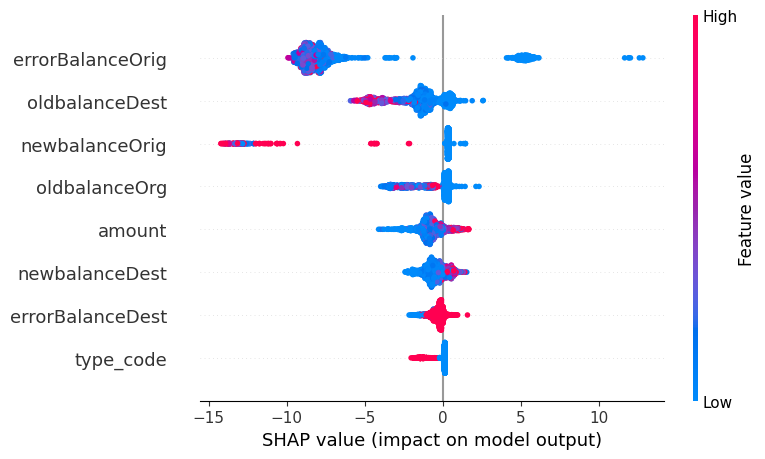

type_code 0.137
amount -1.252
oldbalanceOrg 0.392
newbalanceOrig 0.357
oldbalanceDest -1.219
newbalanceDest -1.092
errorBalanceOrig -7.852
errorBalanceDest -0.361


In [19]:
import shap

explainer = shap.TreeExplainer(model)

# 1. The overall picture (screenshot this for your report)
sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample)

# 2. The reasons for ONE transaction
one_row = X_test.iloc[[0]]
values = explainer.shap_values(one_row)[0]
for name, value in zip(FEATURES, values):
    print(name, round(float(value), 3))

In [20]:
import joblib
import json
import os

os.makedirs("artifacts", exist_ok=True)
joblib.dump(model, "artifacts/model.joblib")  # a folder inside Colab # save the trained model

# Find the cut-off score that gives the best F1-score
scores = model.predict_proba(X_test)[:, 1]
best_threshold = 0.5
best_f1 = 0

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    guesses = (scores >= t).astype(int)
    f1 = f1_score(y_test, guesses)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

# Save the details Django needs
info = {
    "version": "xgb-v1",
    "features": FEATURES,
    "metrics": get_metrics(model),
    "recommended_threshold": round(best_threshold * 100),
}

with open("artifacts/meta.json", "w") as f:
    json.dump(info, f, indent=2)

# Keep a safe copy on Google Drive (Colab files disappear when the session ends)
!cp -r artifacts /content/drive/MyDrive/fraudguard/

# Download the two files to your laptop
from google.colab import files
files.download("artifacts/model.joblib")
files.download("artifacts/meta.json")

# Print the library versions (you need them in the next part)
import sys, xgboost, sklearn, shap, pandas, numpy
print("python      ", sys.version.split()[0])
print("xgboost     ", xgboost.__version__)
print("scikit-learn", sklearn.__version__)
print("shap        ", shap.__version__)
print("pandas      ", pandas.__version__)
print("numpy       ", numpy.__version__)
print("joblib      ", joblib.__version__)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

python       3.13.15
xgboost      3.4.1
scikit-learn 1.6.1
shap         0.52.0
pandas       2.2.3
numpy        2.1.3
joblib       1.6.0
